<div style="border-left:5px solid #67CBEE;padding:10px 16px;background:#F7F9FB;color:#19222D;margin:12px 0"><b>AMD Radeon · YOLO26 · Day 01</b><br><span style="color:#536273">算法 → 数据 → 训练 → 评测 → 证据。每一个结论都应由实际运行结果支撑。</span><br><span style="color:#536273">Algorithm → Data → Training → Evaluation → Evidence. Every conclusion must be backed by real execution results.</span></div>

# 02 / Lab B · 数据集、标注、分离与 QA

**建议时长：40–50 分钟**　｜　学习路径：40–50 minutes

> 请按顺序运行；运行结果必须来自自己的 GPU 环境，不可把示例文字当作实测数据。

---

# 02 / Lab B · Dataset, Annotation, Splits & QA

**Suggested time: 数据来源 → 标注质检 → 防泄漏划分** | Learning path: data source → annotation QA → leak-proof splits

> Run the cells in order; every result must come from your own GPU environment — never present the sample text as measured data.

## 实验目标
- 检查一行 YOLO 标签 `class x_center y_center width height`，五个值中坐标为归一化值。
- 从 COCO128 **原始 128 张图**构造教学用、图片不重叠的 Train/Val/Test；默认只保留 `person/car/chair` 三类，并**不是**快递包裹数据集。
- 检查标签范围、重复图片、边界框与数据集配置。

> **关键科学边界**：官方 COCO128 训练/验证复用同样图片，仅用于冒烟测试。本 Notebook 对其重新分组和划分，尽量防止直接重叠；由于只有 128 张，无法据此宣称工业精度或严格 COCO 基准；语义相似场景泄漏还需人工审查。

---

## Goal
- Parse one YOLO label line `class x_center y_center width height`; the four coordinates are normalized.
- Build a teaching-only, image-disjoint Train/Val/Test from the **original 128 COCO128 images**, keeping only `person/car/chair` — this is **not** a parcel dataset.
- Check label ranges, duplicates, bounding boxes and the dataset config.

> **Key scientific boundary**: official COCO128 reuses the same images for train and val and is for smoke tests only. This notebook re-groups and re-splits them to prevent direct overlap; with just 128 images the result can never be presented as industrial accuracy or a strict COCO benchmark, and semantically similar scenes still need human review.

In [1]:
from pathlib import Path
import os, sys, json
candidates = [Path.cwd(), Path.cwd().parent, Path('/workspace/YOLO26_ROCm_Day1_Labs')]
package = next((p for p in candidates if (p/'course/lab_utils.py').exists()), None)
if package is None:
    raise FileNotFoundError('请先将 ZIP 完整解压，并从项目目录或 notebooks/ 目录启动 Jupyter。')
sys.path.insert(0, str(package))
from course.lab_utils import (root, ensure_dirs, load_config, save_config, write_json,
    write_csv, system_info, require_rocm, sha256)
home = ensure_dirs()
cfg = load_config()
print('Project:', package, '\nPersistent output:', home)

Project: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs 
Persistent output: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check


In [2]:
from course.lab_utils import (download_coco128,prepare_coco128_demo,inspect_dataset,
    plot_labels,read_labels,label_errors,list_images)
from IPython.display import display
from matplotlib import pyplot as plt
# 如果已有自定义数据：设为你的绝对路径，例如 /workspace/my_dataset/data.yaml。
USER_DATA_YAML = os.environ.get('YOLO_USER_DATA_YAML','').strip()
if USER_DATA_YAML:
    yaml_path=Path(USER_DATA_YAML).expanduser().resolve()
    if not yaml_path.is_file(): raise FileNotFoundError(yaml_path)
    save_config({'dataset_yaml':str(yaml_path),'dataset_kind':'user_provided'})
    print('Using user-owned dataset:',yaml_path)
else:
    source=download_coco128(home)
    dest=home/'data/processed/coco128_classroom_3class'
    if (dest/'data.yaml').is_file():
        print('Reusing existing dataset; do not overwrite student corrections automatically.')
    else:
        report=prepare_coco128_demo(source,dest,seed=42)
        print(report)
    yaml_path=dest/'data.yaml'
    save_config({'dataset_yaml':str(yaml_path),'dataset_kind':'COCO128_repartitioned_teaching_only'})
print('Training dataset:',yaml_path)

{'source': 'COCO128 (COCO train2017 first 128 images)', 'pedagogical_only': True, 'note': 'Image-disjoint internal partition; still tiny and biased, not a COCO benchmark, near-duplicate heuristic is not a guarantee.', 'splits': {'train': 89, 'val': 20, 'test': 19}, 'class_counts': {'train:0': 196, 'train:1': 32, 'val:0': 29, 'train:2': 33, 'test:0': 29, 'test:2': 2, 'test:1': 14}, 'groups': 128, 'seed': 42, 'names': ['person', 'car', 'chair'], 'data_yaml': 'C:\\Users\\Rocm\\Desktop\\YOLO\\YOLO26_ROCm_Day1_Labs\\yolo_course_bilingual_check\\data\\processed\\coco128_classroom_3class\\data.yaml', 'source_url': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip'}
Training dataset: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\data\processed\coco128_classroom_3class\data.yaml


In [3]:
qa=inspect_dataset(yaml_path)
print('Class names:',qa['names'])
print('Split stats:',qa['splits'])
print('Errors:',qa['problems'][:30])
print('Near-duplicate review warnings:',qa['warnings'][:10])
write_json(home/'reports/lab_b_dataset_qa.json',{k:v for k,v in qa.items() if k!='sample_paths'})
assert qa['pass'],'发现数据结构错误，请先修复再训练'
print('Dataset structural QA: PASS')

Class names: {0: 'person', 1: 'car', 2: 'chair'}
Split stats: {'train': {'images': 89, 'boxes': 261, 'empty_or_missing_labels': 34}, 'val': {'images': 20, 'boxes': 29, 'empty_or_missing_labels': 12}, 'test': {'images': 19, 'boxes': 45, 'empty_or_missing_labels': 11}}
Errors: []
Near-duplicate review warnings: []
Dataset structural QA: PASS


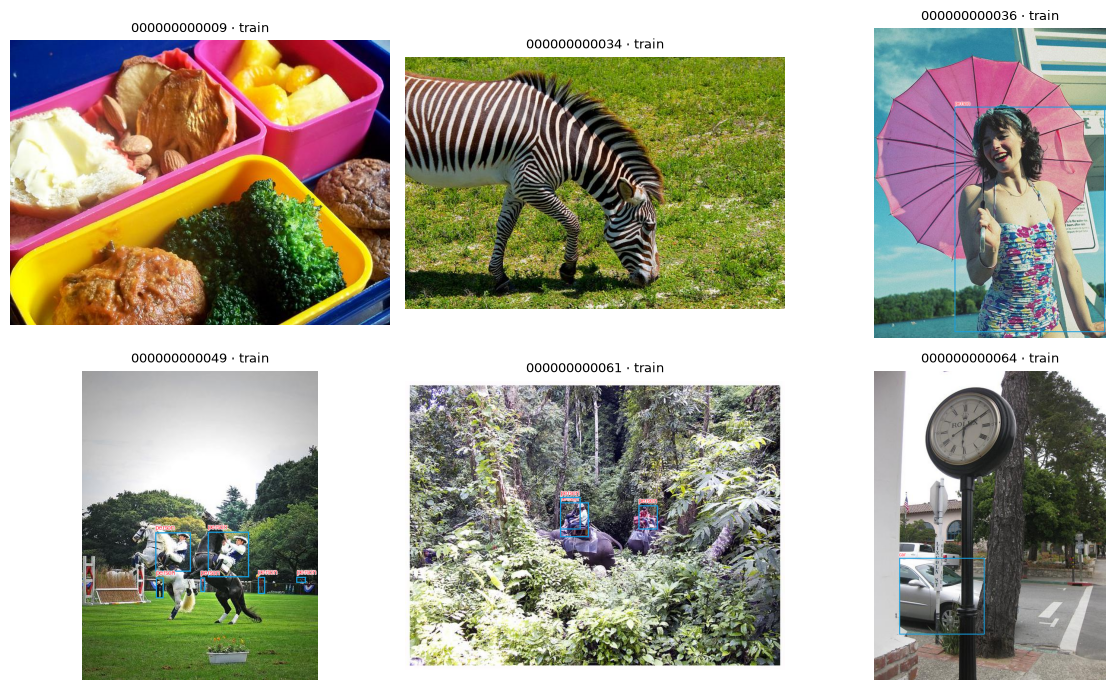

In [4]:
# 可视化训练标签；此步骤由学生人工复核遮挡、错标、漏标等问题
names=list(qa['names'].values()) if isinstance(qa['names'],dict) else list(qa['names'])
train_imgs=qa['sample_paths']['train']
fig=plot_labels(train_imgs,names,6)
fig.savefig(home/'assets/lab_b_label_gallery.png',dpi=150,bbox_inches='tight')
plt.show()

In [5]:
# 代码练习：验证无效标签能够被 QA 捕获，不会污染实际数据集
valid='0 0.5 0.5 0.2 0.3\n'
invalid='0 1.2 0.5 0.2 0.3\n'
assert not label_errors(valid,len(names))
assert label_errors(invalid,len(names))
print('Label format & invalid-bound tests: PASS')

Label format & invalid-bound tests: PASS


In [6]:
# 创建人工审阅清单。不要直接上传敏感/受限图像到公开 GitHub。
review=[{'image':str(img),'label':str(Path(qa['root'])/'labels/train'/f'{img.stem}.txt'),
         'approved':'', 'issue_type':'', 'corrected':'', 'note':''} for img in train_imgs[:20]]
write_csv(home/'reports/lab_b_manual_review.csv',review,
          ['image','label','approved','issue_type','corrected','note'])
print('人工检查 20 张并填写:',home/'reports/lab_b_manual_review.csv')

人工检查 20 张并填写: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\reports\lab_b_manual_review.csv


### 标注修改实操：可审计，默认不写入
选择一张标注图片和其中一行，将新的标签行填写在下面；只有显式设置 `APPLY_CORRECTION=True` 时才会写入，且先备份旧标签。**请先核对人工真值，不可因为预测结果不合预期就任意修改真值标签。**

---

### Hands-on Annotation Correction: auditable, off by default
Pick an annotated image and one label line, then type the corrected line below. Nothing is written unless you explicitly set `APPLY_CORRECTION=True`, and the old label is always backed up first. **Verify against human ground truth first — never bend the truth labels just because predictions disappoint you.**

In [7]:
from course.lab_utils import label_path_for_image
import datetime
TARGET_IMAGE = train_imgs[0]
LABEL_LINE_INDEX = 0  # 一行一个目标，从 0 开始
NEW_LABEL_LINE = '0 0.500000 0.500000 0.200000 0.200000'  # 教学占位，不应盲目写入
CORRECTION_REASON = 'TODO: 请写清楚人工审核依据'
APPLY_CORRECTION = False  # 先通过可视化核对，再显式设为 True
label_file=label_path_for_image(TARGET_IMAGE)
original_lines=label_file.read_text(encoding='utf-8').splitlines()
print('编辑目标:',label_file)
print('原始标签:',original_lines[:3])
if APPLY_CORRECTION:
    assert CORRECTION_REASON and not CORRECTION_REASON.startswith('TODO:')
    assert 0 <= LABEL_LINE_INDEX < len(original_lines), '该图可能是合法的空标签，需要先选择有框的图片'
    assert not label_errors(NEW_LABEL_LINE,len(names))
    old_line=original_lines[LABEL_LINE_INDEX]
    backup=home/'artifacts/label_backups'/f'{label_file.stem}_{datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")}.txt'
    backup.parent.mkdir(parents=True,exist_ok=True)
    backup.write_text(label_file.read_text(encoding='utf-8'),encoding='utf-8')
    original_lines[LABEL_LINE_INDEX]=NEW_LABEL_LINE
    label_file.write_text('\n'.join(original_lines)+'\n',encoding='utf-8')
    write_json(home/'reports/lab_b_last_correction.json',
       {'image':str(TARGET_IMAGE),'label':str(label_file),'before':old_line,'after':NEW_LABEL_LINE,
        'reason':CORRECTION_REASON,'backup':str(backup)})
    assert inspect_dataset(yaml_path)['pass'], '修改后数据集 QA 失败，请恢复备份'
    print('修正已写入，备份：',backup)
else:
    print('安全预览：未修改任何文件。')

编辑目标: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\data\processed\coco128_classroom_3class\labels\train\000000000009.txt
原始标签: []
安全预览：未修改任何文件。


### 思考题 / 面试必答
1. 为什么 Train/Val/Test 必须隔离？同一视频相邻帧能否分到不同集合？
2. 标签缺失与空标签有何区别？哪些空标签是合理的负样本？
3. 为什么 COCO128 不能直接用于可信的模型排行榜成绩？
4. 哪些错误属于标注规范问题而非模型算法问题？

**交付**：`data/processed/.../data.yaml`、`split_manifest.csv`、`dataset_manifest.json`、QA JSON、人工检查表、标注图。

---

### Think / Interview Questions
1. Why must Train/Val/Test stay isolated? May adjacent frames of one video land in different splits?
2. Missing label file vs empty label — what is the difference? Which empty labels are legitimate negatives?
3. Why can't COCO128 directly produce trustworthy leaderboard scores?
4. Which errors are annotation-spec problems rather than model problems?

**Deliverables**: `data/processed/.../data.yaml`, `split_manifest.csv`, `dataset_manifest.json`, the QA JSON, the manual review sheet, annotated images.